# 05 · 🤗 Datasets · Stream: ce poți face cu un `IterableDataset`

**Sursa:** [🤗 Datasets · Stream](https://huggingface.co/docs/datasets/stream)
**Kernel:** `speech-vlm` (Mac)

**Cum folosești ghidul:**
- 📖 **Teorie**: ce trebuie să reții, pe scurt.
- ▶️ **Cod din curs**: îl rulezi și te uiți la rezultat.
- 🔍 **Ce să observi**: unde să te uiți în grafic sau în output.
- 🧪 **Exercițiu**: cerința e în comentariile `# TODO`, iar soluția e chiar dedesubt. O rulezi, apoi o modifici ca să vezi ce se schimbă.
- 🎯 **Legătura cu proiectul**.

> 💾 **Doar seturi mici:** folosim MINDS-14 (deja în cache, ~100 MB) și `librispeech_asr_dummy` (73 de exemple). Nu descărcăm seturi mari.

🎯 **De ce contează:** în proiect citim dataset-ul în streaming și trebuie să-l amestecăm, să-l împărțim, să-l procesăm din mers, să-l grupăm în batch-uri și, dacă Colab se oprește, să reluăm de unde am rămas.

In [1]:
import io, time
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
from datasets import load_dataset, Audio as AudioFeature
from datasets import Dataset, interleave_datasets

/Users/bceachi/miniforge3/envs/speech-vlm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. `IterableDataset` vs `Dataset`

📖 **Teorie**

| | `Dataset` | `IterableDataset` |
|---|---|---|
| Acces | aleator: `ds[i]`, `len(ds)` | doar **iterare** |
| Unde stă | pe disk (Arrow, în cache) | se citește pe rând |
| Bun pentru | explorare, acces aleator | **antrenare** pe date mari |

Un `IterableDataset` îl obții în două feluri:
1. cu `load_dataset(..., streaming=True)`, direct de pe Hub;
2. cu `dataset.to_iterable_dataset(num_shards=...)`, dintr-un `Dataset` local. Varianta asta e **mai rapidă**, pentru că citește din fișierele locale.

Un **shard** e o bucată a dataset-ului. Dataset-urile mari sunt împărțite în multe fișiere, iar fiecare e un shard. Shard-urile permit amestecarea și citirea în paralel.

▶️ Ca să nu descărcăm nimic nou, folosim MINDS-14, deja în cache, transformat în `IterableDataset`:

In [2]:
minds = load_dataset("PolyAI/minds14", name="en-AU", split="train")
it = minds.to_iterable_dataset(num_shards=4)
print(it)
print("primul exemplu:", next(iter(it))["transcription"])
print("coloana 'transcription' (column indexing):", next(iter(it["transcription"])))

IterableDataset({
    features: ['path', 'audio', 'transcription', 'english_transcription', 'intent_class', 'lang_id'],
    num_shards: 4
})
primul exemplu: I would like to pay my electricity bill using my card can you please assist
coloana 'transcription' (column indexing): I would like to pay my electricity bill using my card can you please assist


## 2. Shuffle cu buffer

📖 **Teorie**
- Un `IterableDataset` nu poate amesteca tot dataset-ul, pentru că nu-l are în memorie. Folosește un **buffer**:
  1. umple buffer-ul cu primele `buffer_size` exemple;
  2. scoate unul **la întâmplare** din buffer;
  3. pune în locul lui următorul exemplu din stream.
- **Buffer mic** înseamnă amestecare slabă: exemplele rămân aproape de ordinea inițială. **Buffer mare** înseamnă amestecare mai bună, dar mai multă memorie. Valoarea implicită e `buffer_size=1000`.
- `shuffle` amestecă și **ordinea shard-urilor**.
- **La fiecare epocă:** apelezi `set_epoch(epoch)`. Seed-ul efectiv devine `seed + epoch`, deci altă ordine.

▶️ MINDS-14 e **sortat după intenție**, deci fără shuffle primele exemple au toate aceeași etichetă:

In [3]:
def first_labels(d, k=10):
    return [e["intent_class"] for e in d.select_columns(["intent_class"]).take(k)]

print("fără shuffle:     ", first_labels(it))
print("buffer_size=5:    ", first_labels(it.shuffle(seed=0, buffer_size=5)))
print("buffer_size=1000: ", first_labels(it.shuffle(seed=0, buffer_size=1000)))

fără shuffle:      [13, 13, 13, 13, 13, 13, 13, 13, 13, 13]
buffer_size=5:     [3, 4, 12, 12, 13, 13, 4, 4, 13, 4]
buffer_size=1000:  [13, 3, 13, 6, 7, 0, 4, 7, 10, 2]


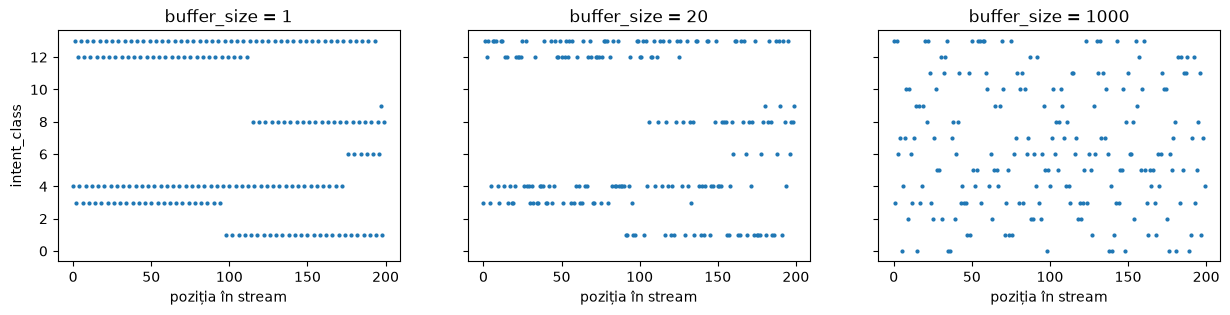

In [4]:
# 🧪 TODO: vizualizează efectul buffer-ului. Desenează eticheta primelor 200 de exemple pentru buffer 1, 20 și 1000.
fig, ax = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for a, b in zip(ax, [1, 20, 1000]):
    labels = first_labels(it.shuffle(seed=0, buffer_size=b), k=200)
    a.plot(labels, ".", ms=4); a.set_title(f"buffer_size = {b}"); a.set_xlabel("poziția în stream")
ax[0].set_ylabel("intent_class")
plt.show()
# Răspuns:
# - buffer = 1 → patru „linii” orizontale: shuffle-ul citește alternativ din cele 4 shard-uri,
#   dar fiecare shard rămâne în ordinea lui (sortat după intenție), deci exemplele în sine nu sunt amestecate;
# - buffer = 20 → amestecare locală;
# - buffer = 1000 → etichetele sunt bine amestecate (buffer-ul încape tot dataset-ul de 654 de exemple).

In [5]:
# 🧪 TODO: arată că set_epoch schimbă ordinea de la o epocă la alta.
from itertools import islice
shuffled = it.select_columns(["intent_class"]).shuffle(seed=0, buffer_size=1000)
for epoch in range(3):
    shuffled.set_epoch(epoch)
    print(f"epoca {epoch}:", [e["intent_class"] for e in islice(shuffled, 10)])   # iterăm DIRECT dataset-ul
# Răspuns: ordinea diferă la fiecare epocă, pentru că seed-ul efectiv devine seed + epoch.
# ⚠️ Capcană (verificată): dacă iterezi prin shuffled.take(10), ordinea rămâne cea de la epoca 0,
#    pentru că un dataset nou, creat cu take(), nu preia epoca. În antrenare iterezi direct dataset-ul.

epoca 0: [13, 3, 13, 6, 7, 0, 4, 7, 10, 2]
epoca 1: [6, 10, 3, 10, 10, 11, 12, 2, 13, 13]
epoca 2: [11, 8, 13, 11, 6, 5, 5, 8, 5, 12]


## 3. Împărțire: `take`, `skip`, `shard`

📖 **Teorie**
- `take(n)` dă **primele n** exemple, iar `skip(n)` dă **tot în afară de primele n**. Împreună îți fac un split train/validare.
- ⚠️ Faci **shuffle înainte** de `take`/`skip`. După ele, ordinea shard-urilor se blochează și nu mai poți amesteca.
- `shard(num_shards, index)` împarte dataset-ul în bucăți. E folosit, de exemplu, ca să dai fiecărui worker al unui DataLoader o bucată diferită.

In [6]:
# 🧪 TODO: fă un split validare / train (50 / restul) după shuffle și verifică faptul că nu se suprapun.
shuffled = it.shuffle(seed=42, buffer_size=1000)
val = shuffled.take(50)
train = shuffled.skip(50)
val_paths = {e["path"] for e in val.select_columns(["path"])}
train_paths = {e["path"] for e in train.select_columns(["path"])}
print(f"val: {len(val_paths)} | train: {len(train_paths)} | comune: {len(val_paths & train_paths)}")
print("shard 0 din 2 →", it.shard(num_shards=2, index=0).num_shards, "shard-uri")
# Răspuns: 50 + 604 = 654, cu 0 exemple comune. Fiecare dintre cele 2 bucăți primește 2 din cele 4 shard-uri.

val: 50 | train: 604 | comune: 0
shard 0 din 2 → 2 shard-uri


## 4. Combinare: `interleave_datasets`

📖 **Teorie**
- `interleave_datasets` **alternează** exemple din mai multe dataset-uri, cu aceleași coloane. Cu `probabilities` controlezi proporțiile.
- **Exemplu de utilizare:** amesteci mai multe surse sau limbi într-un singur stream de antrenare.
- `stopping_strategy` decide când se oprește amestecul:
  - `"first_exhausted"` (implicit): se oprește când se termină primul dataset;
  - `"all_exhausted"`: continuă până trec toate dataset-urile măcar o dată.

In [7]:
# 🧪 TODO: amestecă en-AU și fr-FR (ambele deja în cache) în proporție 80% / 20% și verifică pe 200 de exemple.
fr = load_dataset("PolyAI/minds14", name="fr-FR", split="train").to_iterable_dataset(num_shards=2)
mix = interleave_datasets([it.select_columns(["lang_id"]), fr.select_columns(["lang_id"])], probabilities=[0.8, 0.2], seed=42)
langs = [e["lang_id"] for e in mix.take(200)]
print(f"din 200: en-AU = {langs.count(2)}, fr-FR = {langs.count(6)}")
# Răspuns: aproximativ 80% / 20%, de exemplu 165 / 35.

din 200: en-AU = 165, fr-FR = 35


## 5. Coloane: rename, remove, cast

📖 Funcționează ca la `Dataset`: `rename_column`, `remove_columns`, `select_columns`, `cast_column`.

**Pentru audio:** `cast_column("audio", Audio(sampling_rate=16_000))` resamplează **din mers**, pe măsură ce citești.

In [8]:
it16 = (it.rename_column("transcription", "text")
          .remove_columns(["english_transcription", "lang_id"])
          .cast_column("audio", AudioFeature(sampling_rate=16_000)))
ex = next(iter(it16))
print("coloane:", list(ex.keys()))
print("audio:", ex["audio"]["sampling_rate"], "Hz,", len(ex["audio"]["array"]), "eșantioane")

coloane: ['path', 'audio', 'text', 'intent_class']
audio: 16000 Hz, 124830 eșantioane


## 6. Procesare din mers: `map` și `filter`

📖 **Teorie**
- La un `IterableDataset`, `map` și `filter` **nu rulează imediat**. Se aplică **leneș** (*lazy*), abia când iterezi.
  - Construirea pipeline-ului e instantanee.
  - Munca se face exemplu cu exemplu, la citire.
- `map(..., batched=True)` procesează exemple în grupuri (implicit câte 1000). E util pentru tokenizare.
- `remove_columns` din `map` scoate coloanele **după** ce funcția le-a folosit.

In [9]:
from transformers import WhisperFeatureExtractor
fe = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")

t0 = time.time()
pipeline = (it16
    .map(lambda e: {"duration": len(e["audio"]["array"]) / e["audio"]["sampling_rate"]})
    .filter(lambda e: e["duration"] < 30.0)
    .map(lambda e: {"input_features": fe(e["audio"]["array"], sampling_rate=16000).input_features[0]},
         remove_columns=["audio"]))
print(f"pipeline construit în {time.time() - t0:.3f} s (încă nimic procesat)")

t0 = time.time()
first = next(iter(pipeline))
print(f"primul exemplu procesat în {time.time() - t0:.2f} s")
print("coloane:", list(first.keys()), "| input_features:", np.asarray(first["input_features"]).shape)

pipeline construit în 0.001 s (încă nimic procesat)
primul exemplu procesat în 0.01 s
coloane: ['path', 'text', 'intent_class', 'duration', 'input_features'] | input_features: (80, 3000)


In [10]:
# 🧪 TODO: filtrează doar exemplele sub 5 s și afișează primele 3 durate.
short = it16.map(lambda e: {"duration": len(e["audio"]["array"]) / e["audio"]["sampling_rate"]}).filter(lambda e: e["duration"] < 5.0)
print([round(e["duration"], 2) for e in short.take(3)])
# Răspuns: trei durate, toate sub 5 s. Restul exemplelor sunt sărite la citire, fără să fie păstrate undeva.

[4.18, 2.82, 4.27]


## 7. Batch-uri și bucla de antrenare

📖 **Teorie**
- `batch(batch_size=...)` transformă stream-ul în **grupuri** de exemple, sub forma unui dicționar cu liste. Cu `drop_last_batch=True` arunci ultimul batch, dacă e incomplet.
- La antrenare, un `IterableDataset` se dă direct unui `torch.utils.data.DataLoader`. Cu `with_format("torch")`, valorile devin tensori.

In [11]:
b = next(iter(it.select_columns(["intent_class", "transcription"]).batch(batch_size=4)))
print("batch:", {k: (v if k == "intent_class" else [s[:25] + "…" for s in v]) for k, v in b.items()})

batch: {'intent_class': [13, 13, 13, 13], 'transcription': ['I would like to pay my el…', 'hello I like to pay for B…', 'pay a bill…', 'my credit card payment is…']}


In [12]:
# 🧪 TODO: un DataLoader peste pipeline-ul cu features. Ia 2 batch-uri și afișează shape-urile.
import torch
from torch.utils.data import DataLoader

train_stream = pipeline.select_columns(["input_features", "intent_class"]).with_format("torch")
loader = DataLoader(train_stream, batch_size=4)
for step, batch in enumerate(loader):
    print(f"pasul {step}: input_features {tuple(batch['input_features'].shape)} | intent_class {batch['intent_class'].tolist()}")
    if step == 1:
        break
# Răspuns: (4, 80, 3000) la fiecare pas, adică 4 exemple × 80 de benzi mel × 3000 de cadre. Asta ar intra în encoderul Whisper.
# Observă: toate etichetele sunt 13, pentru că pipeline-ul nu e amestecat (MINDS-14 e sortat după intenție).
# La antrenare pui .shuffle(seed, buffer_size) înainte de map/filter.

pasul 0: input_features (4, 80, 3000) | intent_class [13, 13, 13, 13]
pasul 1: input_features (4, 80, 3000) | intent_class [13, 13, 13, 13]


## 8. Checkpoint și reluare: `state_dict()`

📖 **Teorie**
- Dacă antrenarea se oprește, vrei să reiei de unde ai rămas. Asta e valabil pentru model și optimizer, **dar și pentru date**.
- `IterableDataset.state_dict()` salvează poziția: shard-ul curent și indexul exemplului din el.
- `load_state_dict(...)` reia de acolo. Shard-urile deja parcurse nu se recitesc, deci reluarea e rapidă.
- ⚠️ Cu `shuffle`, exemplele care erau în buffer în momentul salvării **se pierd** la reluare.
- Pentru DataLoader există `StatefulDataLoader`, din `torchdata`.

▶️ **Exemplul din documentație:**

In [13]:
iterable_dataset = Dataset.from_dict({"a": range(6)}).to_iterable_dataset(num_shards=3)
for idx, example in enumerate(iterable_dataset):
    print(example)
    if idx == 2:
        state_dict = iterable_dataset.state_dict()
        print("checkpoint")
        break
iterable_dataset.load_state_dict(state_dict)
print("restart from checkpoint")
for example in iterable_dataset:
    print(example)

{'a': 0}
{'a': 1}
{'a': 2}
checkpoint
restart from checkpoint
{'a': 3}
{'a': 4}
{'a': 5}


🔍 **Ce să observi:** după reluare continuă cu `{'a': 3}`, exact de unde rămăsese.

🎯 **Legătura cu proiectul:**
- Pe Colab, sesiunea se poate opri. Atunci reluăm din checkpoint-ul de pe HF Hub ([COLAB.md](../../00_setup/COLAB.md#checkpoint-uri-cum-salvăm-și-cum-reluăm)).
- Trainer-ul se ocupă de model și de optimizer. **Poziția în date** contează la fel de mult: fără ea, la reluare ai reveni la începutul stream-ului.

## 9. Alte lucruri utile (doar teorie)
- **Doar anumite coloane sau rânduri din Parquet:** `load_dataset(..., streaming=True, columns=[...], filters=[...])` citește doar coloanele cerute și sare peste rândurile care nu trec filtrul. E util când vrei doar textul dintr-un dataset audio uriaș.
- **Salvare:**
  - `push_to_hub("user/nume")` urcă un `IterableDataset` procesat pe Hub, ca Parquet;
  - `to_parquet`, `to_csv` și `to_json` îl exportă local.

## 📌 Ce trebuie să reții
- `IterableDataset` = doar iterare. Îl obții cu `streaming=True` sau cu `to_iterable_dataset(num_shards=...)`, care e mai rapid din fișiere locale.
- **Shuffle cu buffer:** un buffer mare amestecă mai bine. Între epoci apelezi `set_epoch`. Funcționează doar când iterezi **direct** dataset-ul, nu un `.take()` creat din el.
- **Faci shuffle înainte de `take`/`skip`**, cu care faci split-ul train/validare.
- `interleave_datasets` amestecă surse, cu proporțiile date de `probabilities`.
- `map` și `filter` sunt **leneșe**: rulează la iterare. `cast_column` resamplează din mers.
- `batch()` grupează exemplele, iar `DataLoader` le duce la model.
- `state_dict()` și `load_state_dict()` reiau iterarea după o întrerupere. Exemplele din buffer-ul de shuffle se pierd.

## ❓ Verifică-te
<details><summary><b>1. Cum amestecă un `IterableDataset` fără să aibă tot dataset-ul în memorie?</b></summary>

Cu un **buffer**: ține `buffer_size` exemple, scoate unul la întâmplare și pune în locul lui următorul din stream. Amestecă și ordinea shard-urilor.

</details>

<details><summary><b>2. De ce faci shuffle înainte de `take`/`skip`?</b></summary>

`take` și `skip` blochează ordinea shard-urilor, așa că după ele nu mai poți amesteca. Dacă ai face split-ul înainte de shuffle, nu ar fi aleator.

</details>

<details><summary><b>3. Când rulează de fapt un `map` pe un `IterableDataset`?</b></summary>

**La iterare**, exemplu cu exemplu. Construirea pipeline-ului nu procesează nimic.

</details>

<details><summary><b>4. Ce face `interleave_datasets(..., probabilities=[0.8, 0.2])`?</b></summary>

Alternează exemple din cele două dataset-uri, ~80% din primul și ~20% din al doilea.

</details>

<details><summary><b>5. Cum reiei citirea datelor după o întrerupere?</b></summary>

Salvezi `ds.state_dict()` odată cu checkpoint-ul și apelezi `ds.load_state_dict(...)` la reluare. Exemplele aflate în buffer-ul de shuffle se pierd.

</details>

<details><summary><b>6. De ce `to_iterable_dataset` e mai rapid decât `streaming=True`?</b></summary>

Citește din fișierele locale, din cache, nu prin rețea de pe Hub.

</details>

## ➡️ Următorul pas
Cu ghidurile 01–05 ai toată teoria etapei 01. Urmează:
1. spec-ul [01_dataset](../../../specs/01_dataset.md), pe care îl discutăm împreună;
2. TASK-urile din §2 ale notebook-ului mentorului, pe dataset-ul real.